
 **Heart Disease Prediction**


**Importing essential libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [3]:
import pandas as pd

df = pd.read_csv("Heart_Disease_Prediction.csv")

print(df.shape)
print(df["target"].value_counts(dropna=False))

(1025, 14)
target
1    526
0    499
Name: count, dtype: int64


**Importing and understanding our dataset**

**Verifying it as a 'dataframe' object in pandas**

In [4]:
type(df)

pandas.DataFrame

Shape of dataset

In [5]:
df.shape

(1025, 14)

In [6]:
df.head(5)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [7]:
df.describe()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [9]:
info = ["age","1: male, 0: female","chest pain type, 1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic","resting blood pressure"," serum cholestoral in mg/dl","fasting blood sugar > 120 mg/dl","resting electrocardiographic results (values 0,1,2)"," maximum heart rate achieved","exercise induced angina","oldpeak = ST depression induced by exercise relative to rest","the slope of the peak exercise ST segment","number of major vessels (0-3) colored by flourosopy","thal: 3 = normal; 6 = fixed defect; 7 = reversable defect"]



for i in range(len(info)):
    print(df.columns[i]+":\t\t\t"+info[i])

age:			age
sex:			1: male, 0: female
cp:			chest pain type, 1: typical angina, 2: atypical angina, 3: non-anginal pain, 4: asymptomatic
trestbps:			resting blood pressure
chol:			 serum cholestoral in mg/dl
fbs:			fasting blood sugar > 120 mg/dl
restecg:			resting electrocardiographic results (values 0,1,2)
thalach:			 maximum heart rate achieved
exang:			exercise induced angina
oldpeak:			oldpeak = ST depression induced by exercise relative to rest
slope:			the slope of the peak exercise ST segment
ca:			number of major vessels (0-3) colored by flourosopy
thal:			thal: 3 = normal; 6 = fixed defect; 7 = reversable defect


**Analysing the 'target' variable**

In [10]:
df["target"].describe()

count    1025.000000
mean        0.513171
std         0.500070
min         0.000000
25%         0.000000
50%         1.000000
75%         1.000000
max         1.000000
Name: target, dtype: float64

In [11]:
df["target"].unique()

array([0, 1])

Clearly, this is a classification problem, with the target variable having values '0' and '1'

**Checking correlation between columns**





In [12]:
df['target'] = df['target'].map({'Presence': 1, 'Absence': 0})

In [13]:
print(df.corr()["target"].abs().sort_values(ascending=False))

age        NaN
sex        NaN
cp         NaN
trestbps   NaN
chol       NaN
fbs        NaN
restecg    NaN
thalach    NaN
exang      NaN
oldpeak    NaN
slope      NaN
ca         NaN
thal       NaN
target     NaN
Name: target, dtype: float64


**Exploratory Data Analysis (EDA)**

First, analysing the target variable

In [14]:
X = df.drop("target", axis=1)
Y = df["target"]

Series([], Name: count, dtype: int64)


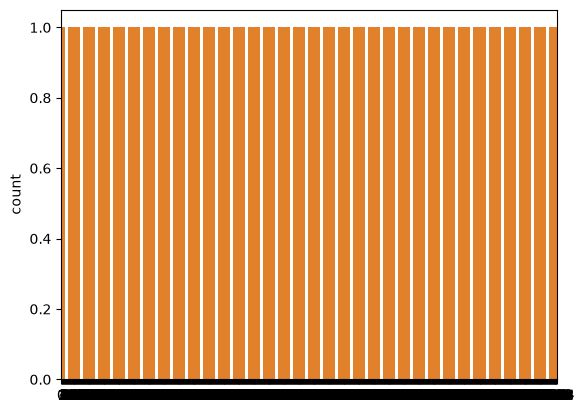

In [15]:
y = df["target"]

sns.countplot(y)
y = df["target"]

sns.countplot(y)


target_temp = df["target"].value_counts()

print(target_temp)

We'll analyse 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca' and 'thal' features

**Analysing the 'Sex' feature**

In [16]:
df["sex"].unique()

array([1, 0])

<Axes: xlabel='sex', ylabel='target'>

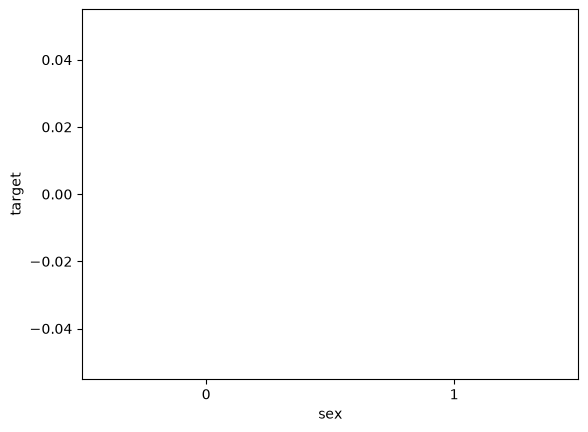

In [17]:
sns.barplot(x=df["sex"],y=y)

We notice, that females are more likely to have heart problems than males

**Analysing the 'Chest Pain Type' feature**

In [18]:
df["cp"].unique()

array([0, 1, 2, 3])

<Axes: xlabel='cp', ylabel='target'>

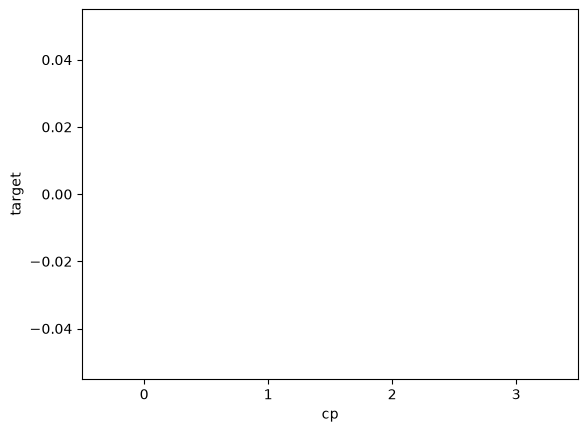

In [19]:
sns.barplot(x=df["cp"],y=y)

We notice, that chest pain of '0', i.e. the ones with typical angina are much less likely to have heart problems

**Analysing the FBS feature**


In [20]:
df["fbs"].describe()

count    1025.000000
mean        0.149268
std         0.356527
min         0.000000
25%         0.000000
50%         0.000000
75%         0.000000
max         1.000000
Name: fbs, dtype: float64

<Axes: xlabel='fbs', ylabel='target'>

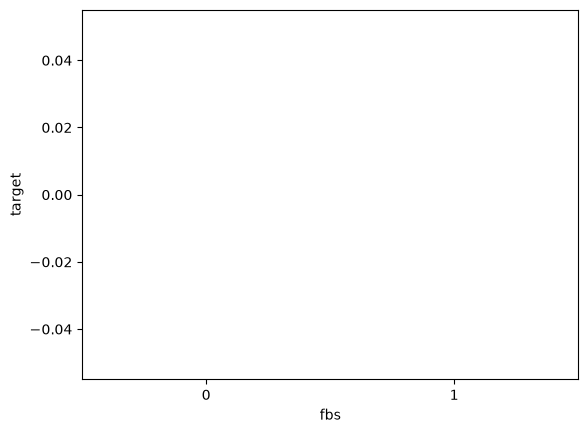

In [21]:
sns.barplot(x=df["fbs"],y=y)

Nothing extraordinary here

**Analysing the EKG results feature**

In [22]:
df["restecg"].unique()

array([1, 0, 2])

<Axes: xlabel='restecg', ylabel='target'>

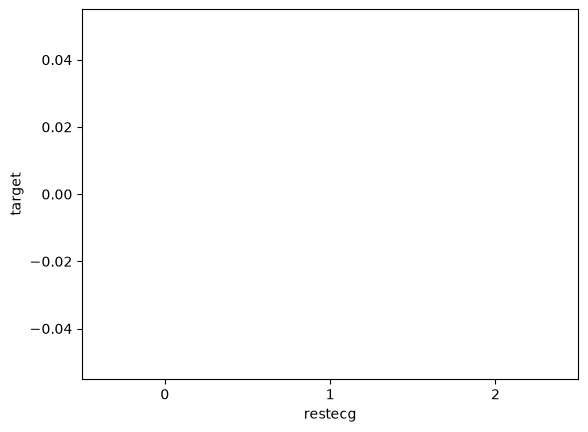

In [23]:
sns.barplot(x=df["restecg"],y=y)

We realize that people with EKG result  '1' and '0' are much more likely to have a heart disease than with EKG result  '2'

**Analysing the 'Exercise angina' feature**

In [24]:
df["exang"].unique()

array([0, 1])

<Axes: xlabel='exang', ylabel='target'>

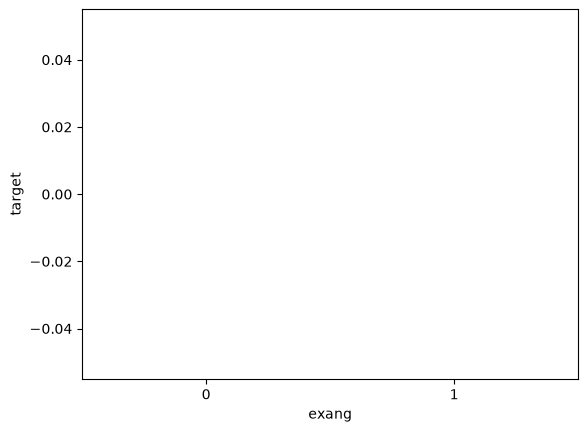

In [25]:
sns.barplot(x=df["exang"],y=y)

People with Exercise angina=1 i.e. Exercise induced angina are much less likely to have heart problems

**Analysing the Slope of ST**

In [26]:
df["slope"].unique()

array([2, 0, 1])

<Axes: xlabel='slope', ylabel='target'>

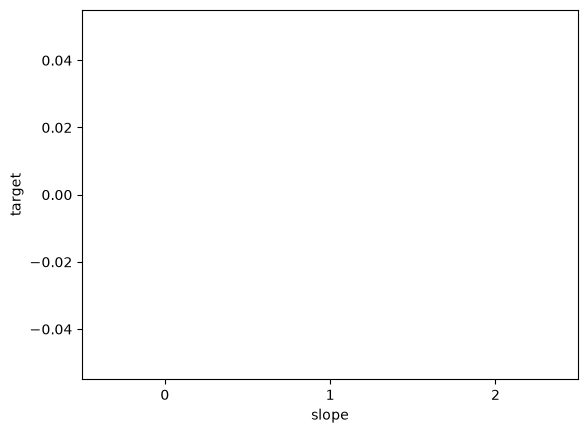

In [27]:
sns.barplot(x=df["slope"],y=y)

We observe, that Slope '2' causes heart pain much more than Slope '0' and '1'

 **Analysis  Number of vessels fluro,Thallium,ST depression,BP**

In [28]:
df["ca"].unique()

array([2, 0, 1, 3, 4])

<Axes: xlabel='ca', ylabel='target'>

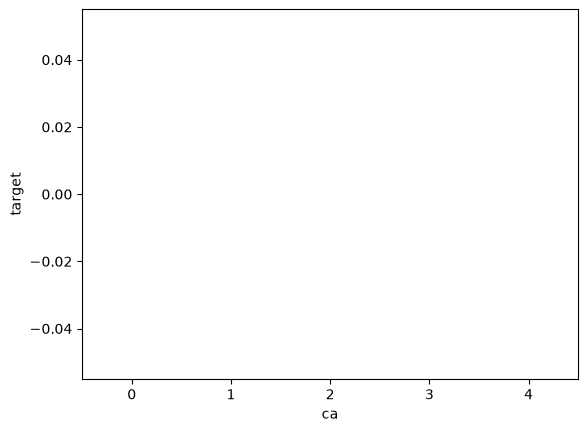

In [29]:
sns.barplot(x=df["ca"],y=y)

In [30]:
df["thal"].unique()

array([3, 2, 1, 0])

<Axes: xlabel='thal', ylabel='target'>

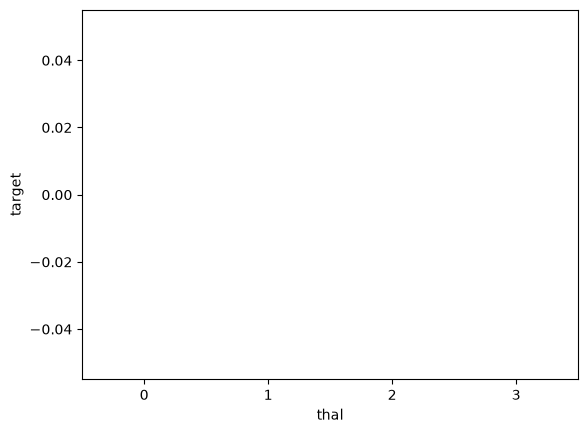

In [31]:
sns.barplot(x=df["thal"],y=y)

**Train Test split**

In [32]:
from sklearn.model_selection import train_test_split

predictors = df.drop("target",axis=1)
target = df["target"]

X_train,X_test,Y_train,Y_test = train_test_split(predictors,target,test_size=0.20,random_state=0)

In [33]:
X_train.shape

(820, 13)

In [34]:
X_test.shape

(205, 13)

In [35]:
Y_train.shape

(820,)

In [36]:
Y_test.shape

(205,)

**Model Fitting**

In [37]:
print(Y_train.isna().sum())
print(Y_test.isna().sum())

820
205


In [40]:
print("Missing values in Y_train:", Y_train.isna().sum())
print("Missing values in Y_test:", Y_test.isna().sum())

Missing values in Y_train: 820
Missing values in Y_test: 205


In [38]:
from sklearn.metrics import accuracy_score

**Logistic Regression**

In [45]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()

lr.fit(X_train,Y_train)

Y_pred_lr = lr.predict(X_test)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [46]:
score_lr = round(accuracy_score(Y_pred_lr,Y_test)*100,2)

print("The accuracy score achieved using Logistic Regression is: "+str(score_lr)+" %")

The accuracy score achieved using Logistic Regression is: 83.41 %


**K Nearest Neighbors**

In [47]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=7)
knn.fit(X_train,Y_train)
Y_pred_knn=knn.predict(X_test)

In [48]:
score_knn = round(accuracy_score(Y_pred_knn,Y_test)*100,2)

print("The accuracy score achieved using KNN is: "+str(score_knn)+" %")

The accuracy score achieved using KNN is: 69.27 %


**SVM**

In [49]:
from sklearn import svm

sv = svm.SVC(kernel='linear')

sv.fit(X_train, Y_train)

Y_pred_svm = sv.predict(X_test)

In [50]:
score_svm = round(accuracy_score(Y_pred_svm,Y_test)*100,2)

print("The accuracy score achieved using Linear SVM is: "+str(score_svm)+" %")

The accuracy score achieved using Linear SVM is: 81.46 %


**Linear Regression**

In [51]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
model = LinearRegression()
model.fit(X_train, Y_train)
y_pred = model.predict(X_test)

In [52]:
mse = mean_squared_error(Y_test, y_pred)
r2 = r2_score(Y_test, y_pred)

print(f"Mean Squared Error: {mse}")
print(f"R^2 Score: {r2}")

Mean Squared Error: 0.12352219579522296
R^2 Score: 0.5056171163529288


In [53]:
y_pred_binary = [1 if pred >= 0.5 else 0 for pred in y_pred]


accuracy = accuracy_score(Y_test, y_pred_binary)
score_Lir = round(accuracy_score(Y_pred_svm,Y_test)*100,2)


print(f"The accuracy score achieved using Linear Regression is: {round(accuracy * 100, 2)} %")

The accuracy score achieved using Linear Regression is: 80.49 %


**Random Forest**

In [55]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

max_accuracy = 0

for x in range(10):
    rf = RandomForestClassifier(
        random_state=x,
        n_estimators=100,
        n_jobs=-1
    )

    rf.fit(X_train, Y_train)

    Y_pred_rf = rf.predict(X_test)

    current_accuracy = round(
        accuracy_score(Y_test, Y_pred_rf) * 100, 2
    )

    if current_accuracy > max_accuracy:
        max_accuracy = current_accuracy
        best_rf = rf
        best_prediction = Y_pred_rf

print("Best Random Forest accuracy:", max_accuracy)

Best Random Forest accuracy: 100.0


In [56]:
rf = RandomForestClassifier(random_state=best_x)
rf.fit(X_train,Y_train)
Y_pred_rf = rf.predict(X_test)

In [57]:
score_rf = round(accuracy_score(Y_pred_rf,Y_test)*100,2)

print("The accuracy score achieved using Decision Tree is: "+str(score_rf)+" %")

The accuracy score achieved using Decision Tree is: 100.0 %


**Decision Tree**


In [58]:
from sklearn.tree import DecisionTreeClassifier

max_accuracy = 0


for x in range(200):
    dt = DecisionTreeClassifier(random_state=x)
    dt.fit(X_train,Y_train)
    Y_pred_dt = dt.predict(X_test)
    current_accuracy = round(accuracy_score(Y_pred_dt,Y_test)*100,2)
    if(current_accuracy>max_accuracy):
        max_accuracy = current_accuracy
        best_x = x

In [59]:
dt = DecisionTreeClassifier(random_state=best_x)
dt.fit(X_train,Y_train)
Y_pred_dt = dt.predict(X_test)

In [60]:
score_dt = round(accuracy_score(Y_pred_dt,Y_test)*100,2)

print("The accuracy score achieved using Decision Tree is: "+str(score_dt)+" %")

The accuracy score achieved using Decision Tree is: 98.54 %


In [63]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

ModuleNotFoundError: No module named 'tensorflow'

In [62]:
model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train.shape[1],)),  # First hidden layer
    Dense(8, activation='relu'),  # Second hidden layer
    Dense(1, activation='sigmoid')  # Output layer
])

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(X_train, Y_train, epochs=50, batch_size=32, validation_split=0.2, verbose=1)

# Evaluate the model
loss, accuracy = model.evaluate(X_test, Y_test)
print(f"Accuracy on the test set: {round(accuracy * 100, 2)} %")

# Predict on the test set
y_pred_prob = model.predict(X_test)
y_pred = [1 if prob >= 0.5 else 0 for prob in y_pred_prob]

# Calculate accuracy score
score_value_ann = round(accuracy_score(Y_test, y_pred) * 100, 2)
print(f"The accuracy score achieved using the ANN model is: {accuracy_score_value} %")

NameError: name 'Sequential' is not defined

**Output final score**

In [ ]:
scores = [score_lr,score_Lir,score_svm,score_knn,score_dt,score_rf,score_value_ann]
algorithms = ["Logistic Regression","Linear Regression","SVM","K-Nearest Neighbors","Decision Tree","Random Forest"," Artificial Neural Network"]

for i in range(len(algorithms)):
    print("The accuracy score achieved using "+algorithms[i]+" is: "+str(scores[i])+" %")

In [ ]:
sns.set(rc={'figure.figsize':(15,8)})
plt.xlabel("Algorithms")
plt.ylabel("Accuracy score")


# Create a DataFrame from the algorithms and scores lists
data = pd.DataFrame({'Algorithm': algorithms, 'Accuracy': scores})

colors = sns.color_palette("husl", len(algorithms))

# Use the DataFrame in the barplot function with the 'x' and 'y' arguments specified
sns.barplot(x='Algorithm', y='Accuracy', data=data, palette=colors)

**random forest  and Decision tree has good result as compare to other algorithms**

In [43]:
# Reload the correct dataset
df = pd.read_csv("Heart_Disease_Prediction.csv")

# Separate input features and target
X = df.drop("target", axis=1)
Y = df["target"]

# Check target values
print("Missing values:", Y.isna().sum())
print("Target distribution:")
print(Y.value_counts())

Missing values: 0
Target distribution:
target
1    526
0    499
Name: count, dtype: int64


In [44]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y,
    test_size=0.2,
    random_state=42,
    stratify=Y
)

print("Training missing values:", Y_train.isna().sum())
print("Testing missing values:", Y_test.isna().sum())

Training missing values: 0
Testing missing values: 0
